# Model selection: `cvrisk`, AIC, and comparison tools

The number of boosting iterations `mstop` is the main regularizer. Too few
underfits; too many overfits. Choose it by estimating out-of-sample risk.

In [1]:
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(5)
n = 300
x = rng.uniform(-3, 3, n)
y = np.sin(x) + rng.normal(scale=0.5, size=n)
fit = mb.gamboost("y ~ bbs(x, df=4)", data={"x": x, "y": y},
                  family=mb.Gaussian(), control=mb.boost_control(500, 0.1))

## Cross-validated risk

Before tuning, look at the in-bag risk to gauge convergence:

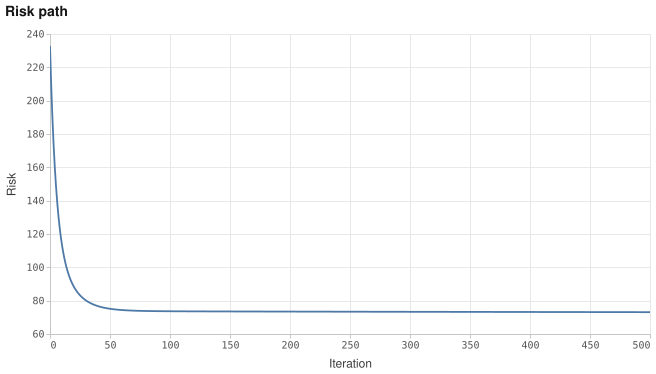

In [2]:
fit.plot_risk()

Then `cvrisk` refits on resampled folds and tracks risk vs iteration. Three resampling
schemes are available:

In [3]:
cv_boot = fit.cvrisk(type="bootstrap", B=25, seed=0)
cv_kf   = fit.cvrisk(type="kfold", B=10, seed=0)
cv_sub  = fit.cvrisk(type="subsampling", B=25, seed=0)
for name, cv in [("bootstrap", cv_boot), ("kfold", cv_kf), ("subsampling", cv_sub)]:
    print(f"{name:12s} optimal mstop = {cv.optimal_mstop}")

bootstrap    optimal mstop = 74
kfold        optimal mstop = 97
subsampling  optimal mstop = 75


A `CvRiskResult` exposes `optimal_mstop`, the per-fold `risk_matrix`, and the
`aggregate` mean risk directly (a column mean across folds, matching R's
`colMeans`).

For custom analysis or export, `cv.to_frame()`
returns a tidy long-format table (one row per fold × mstop, with `risk`,
`aggregate_risk`, and an `is_optimal` flag) in the format of your choice
(`output="polars"`, `"pandas"`, or `"records"`). `StabSelResult` has a matching
`.to_frame()` (one row per candidate learner; see [](stability_selection.ipynb)).

## Fold designs and reports: `folds=` and `report()`

The same three steps choose a stopping point for a standard and a
distributional fit: name a fold design, cross-validate the fitted model, and
read the result's report.

```python
folds = mb.repeated_kfold_folds(n, k=5, repeats=1, seed=1)   # a FoldScheme

gam = mb.gamboost("y ~ bbs(x)", data=data, control=mb.boost_control(200))
report = gam.cvrisk(folds=folds).report()
report.optimum            # an int: one step count
best_gam = gam[report.optimum]

lss = mb.gamboostLSS({"mu": "y ~ bbs(x)", "sigma": "y ~ bols(x)"}, data=data,
                     families=mb.GaussianLSS(), control=mb.boost_control(200))
report = lss.cvrisk(folds=folds).report()
report.optimum            # {"mu": ..., "sigma": ...}: one count per parameter
best_lss = lss.update(mstop=report.optimum)
```

Both reports are a `CvReport`: `folds` names the design, `n_folds` counts
it, `grid` lists the budgets evaluated, `optimum` is the chosen budget,
`risk_at_optimum` is the mean held-out risk there (the family's loss per
unit of held-out observation weight, as `score` says), and `at_boundary` is
true when the optimum is the largest budget searched, so a longer path may do
better.

The grids differ because the questions differ. A standard model has one step
count, and every count up to the fitted `mstop` is read off each fold's path,
so its grid is `0, 1, ..., mstop`. A distributional (LSS: location, scale and shape) model has one count per
parameter. Its default grid is the diagonal, where every parameter gets the
same count, ten points up to the fitted budget; `make_grid_lss` builds an
independent grid per parameter, at more fits. In non-cyclic LSS fitting, each step updates only the parameter whose update most lowers the risk, so the fit has a
single total budget, which its report names `"total"`.

The defaults differ too. Without `folds=`, a standard model's `cvrisk()` uses
25 bootstrap draws (upstream's default) and an LSS model's uses 5-fold
cross-validation. Passing the same named scheme, as above, puts both on one
design. `cv_weights(n, type, B)` returns a bare in-bag weight matrix: use it
where a matrix is expected or to reproduce an R `cv()` call. The named
constructors (`repeated_kfold_folds`, `grouped_folds`, `blocked_folds`,
`rolling_folds`, `loo_folds`, `stratified_folds`) return a `FoldScheme`, which
also carries what a matrix cannot: groups, strata, time order, and rows held
out without being scored. For a curve that is still falling at the end of the
grid, `tune_mstop` extends the path until the risk turns.

## Preprocessing during cross-validation

`cvrisk(preprocessing="fixed")`, the default, evaluates boosting conditional
on the full-data transformations and spline boundaries, following mboost.
`preprocessing="refit"` evaluates the procedure that learns those quantities
from the training sample: each fold estimates its transformation parameters
and data-dependent basis boundaries on its training rows, then uses that
recipe to predict its held-out rows. Explicitly supplied boundaries remain
part of the specification.

The following comparison uses one random five-fold partition for both modes.
`scale(x)` subtracts a fitted mean and divides by a fitted sample standard
deviation; the refitted mode estimates them separately in each training fold.


In [4]:
recipe_data = {"x": x, "y": y}
recipe_fit = mb.gamboost(
    "y ~ bbs(scale(x), df=4)", data=recipe_data,
    control=mb.boost_control(100, 0.1),
)
recipe_folds = mb.cv_weights(n, type="kfold", B=5, seed=12)


In [5]:
# Reuse the partition so the curves differ only in preprocessing policy.
recipe_cv_fixed = recipe_fit.cvrisk(folds=recipe_folds, preprocessing="fixed")
recipe_cv_refit = recipe_fit.cvrisk(folds=recipe_folds, preprocessing="refit")
recipe_report = recipe_cv_refit.report()
print(f"Preprocessing: {recipe_report.preprocessing}; chosen mstop: {recipe_report.optimum}")


Preprocessing: refit; chosen mstop: 99


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 99 is within 5% of the search cap 100; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


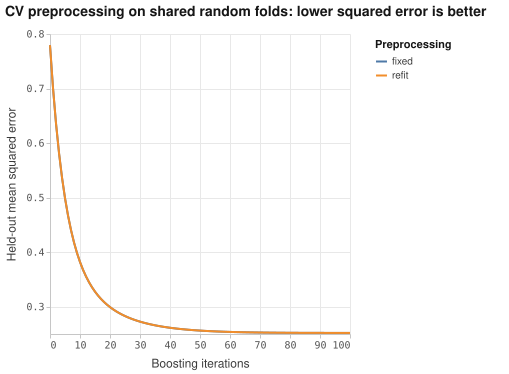

In [6]:
import polars as pl
import altair as alt

recipe_curves = []
for mode, result in [("fixed", recipe_cv_fixed), ("refit", recipe_cv_refit)]:
    curve = (result.to_frame(output="polars").group_by("mstop")
             .agg(pl.first("aggregate_risk").alias("risk"))
             .with_columns(pl.lit(mode).alias("preprocessing")))
    recipe_curves.append(curve)

alt.Chart(pl.concat(recipe_curves)).mark_line().encode(
    x=alt.X("mstop:Q", title="Boosting iterations"),
    y=alt.Y("risk:Q", title="Held-out mean squared error", scale=alt.Scale(zero=False)),
    color=alt.Color("preprocessing:N", title="Preprocessing"),
).properties(title="CV preprocessing on shared random folds: lower squared error is better")


Each curve is the mean held-out squared error across the same five folds.
Its minimum chooses a stopping point within that validation procedure; an
independent test sample is needed to assess the resulting selected model.
The refitted curve describes learning preprocessing on new training samples.
The fixed curve describes resampling a design whose transformations and
boundaries have already been chosen. Their difference can be small when
training-fold ranges and transformation parameters are similar.

The mode is available on standard `glmboost` and `gamboost` models in both
frontends. R uses `cvrisk(model, folds=folds, preprocessing="refit")`.
Refitted folds run sequentially, using native fitting, prediction and family
scoring. Multinomial class-coordinate replay, data-dependent user designs and
neighbourhood graphs, and response transformations whose scale changes across
folds need additional support for reconstructing and scoring their designs,
so this mode rejects them.


## The risk curve

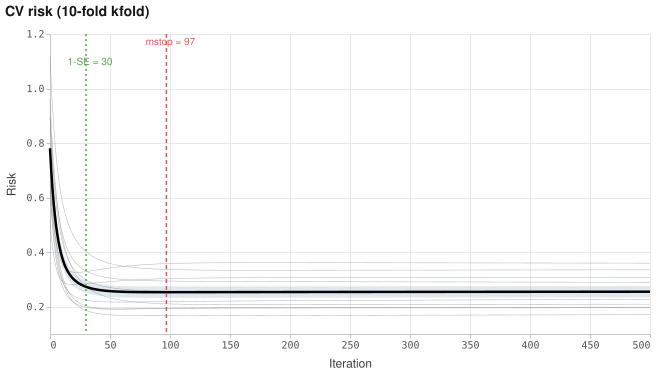

In [7]:
mb.plot.plot_cvrisk(cv_kf)

The mean out-of-sample risk falls, bottoms out at the optimal `mstop`, then rises
as the model overfits. Use that iteration for prediction:

In [8]:
m_opt = cv_kf.optimal_mstop
yhat = fit.predict(mstop=m_opt)
print("m_opt:", m_opt)

m_opt: 97


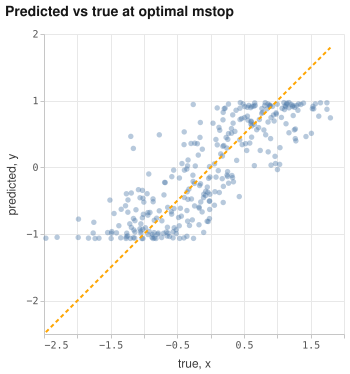

In [9]:
import polars as pl
import altair as alt
alt.Chart(pl.DataFrame({"true": y, "predicted": yhat})).mark_circle(opacity=0.4).encode(
    x="true", y="predicted"
).properties(title="Predicted vs true at optimal mstop") + alt.Chart(
    pl.DataFrame({"x": [y.min(), y.max()], "y": [y.min(), y.max()]})
).mark_line(color="orange", strokeDash=[4, 3]).encode(x="x", y="y")

You can also compose the CV risk plot with the in-bag risk plot:

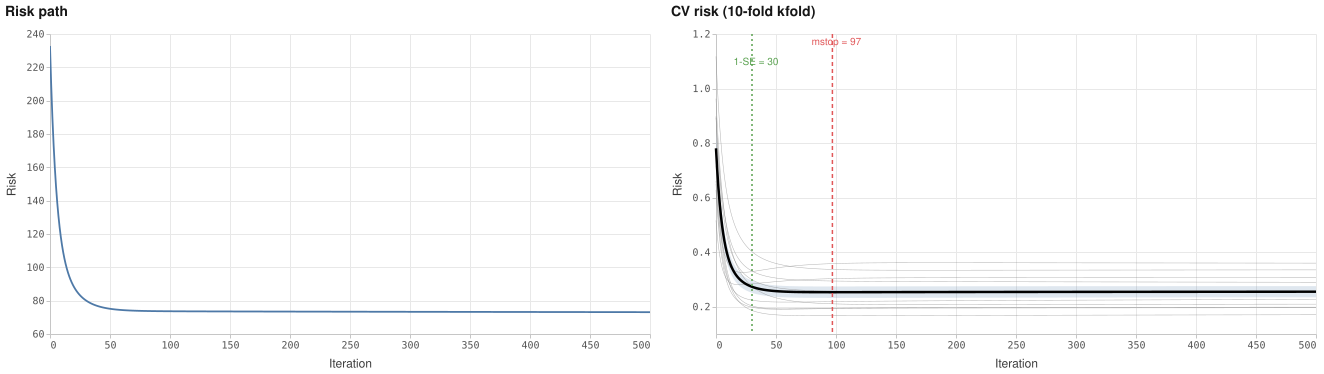

In [10]:
import altair as alt
alt.hconcat(fit.plot_risk(), mb.plot.plot_cvrisk(cv_kf))

## Step count beyond the grid: `tune_mstop`

A cross-validated curve can only turn inside the grid it was computed on. When
its minimum is at the last iteration, the risk was still falling there, and the
reported optimum is where the path stopped rather than where the risk turns.
`tune_mstop` fits a formula once per fold at a starting number of iterations,
reads the aggregated held-out risk at every iteration of that path, and doubles
the grid while the minimum lies in its last 2%, up to `extensions` times. Each
grid costs one fit per fold. The call below starts deliberately short, at 50
iterations:

In [11]:
tuning = mb.tune_mstop("y ~ bbs(x, df=4)", {"x": x, "y": y}, folds=5, start=50)
print(tuning.sentence)
print(f"mstop {tuning.mstop}; grid {tuning.first_largest} -> {tuning.largest}; "
      f"fits {tuning.fits}; still at the boundary: {tuning.at_boundary}")

the risk was still falling at 50, so the grid was extended to 100; the cross-validated risk turns at 92 of 100 iterations tried
mstop 92; grid 50 -> 100; fits 5; still at the boundary: False


The first grid ended at {eval}`tuning.first_largest` iterations and the last at
{eval}`tuning.largest`; the risk is lowest at {eval}`tuning.mstop`, and the
search cost {eval}`tuning.fits` fits. `tuning.sentence` is the same text
`autospec` prints in its step-count line. `folds=` also takes a fold matrix or
a scheme from `mboostrs.folds`, such as `grouped_folds`, so the step count is
chosen for the prediction task the folds describe. With few groups, which
groups share a fold moves a score by as much as the difference between two
specifications; `grouped_folds(..., repeats=)` deals the groups several times
and scores over every deal, and `compare_specifications` and `term_report`
then compute their paired standard errors within each deal. When `at_boundary` is still
true after the last extension, the reported `mstop` is a floor.

Evaluating a group term (`brandom`, `bmrf`) on folds that split its groups —
rows of one group held out while other rows of the same group train the
fold — draws a warning from `cv_risk` and from every function built on it: that
fold's score partly rewards memorized level effects, and folds that keep
each group on one side measure prediction in new groups instead.

## Step length: `boost_control(step=)`

`boost_control(step=)` chooses how far each boosting
step goes once the winning learner is selected. The default `"fixed"` takes
the classic constant step `nu·h` that `mboost` takes. `step="line_search"`
first finds the multiple `rho` of the winner's direction that minimizes the
training loss, then takes `nu·rho·h`: `nu` becomes a fraction of the
loss-optimal step, so one setting means the same amount of progress whatever
the response scale. A fixed `nu` does not: for counts around 150 the step
is about `nu·mean` Newton steps and the linear predictor overflows `exp` at
the second iteration (the same divergence R reports); at a 2% event rate the
step is about twelve times smaller than a Newton step and the fit spends
thousands of iterations. The search costs a handful of `O(n)` loss
evaluations per step, selection is unchanged, the squared-error families are
bit-identical either way (their least-squares step is already optimal,
`rho = 1`), and the rule travels with the model: `cvrisk`, `stabsel`,
`update`, `continue_to` and the bootstrap and conformal refits all carry
it. The non-cyclic LSS method refuses it, naming its reason.

## Long paths: step size and penalization drift

Two properties of component-wise boosting show only on long paths
{cite}`schulte2025additive`, and `gamboost` warns about both.

**Step size.** Each boosting step moves `nu` times the least-squares fit to the
negative gradient. For a loss with strong curvature the step can overshoot, and
the training risk then rises and falls instead of decreasing. On a 300-row
Poisson example at `nu=0.5` the in-bag risk rose on 56 of 100 steps, by up to
2.3 times. A fixed-step fit whose training risk rises by more than 1% warns and
suggests a smaller `nu` or `step="line_search"`.

**Penalization drift.** A learner's `df=` (or `lambda=`) sets the flexibility
of one step, not of the fitted term. A penalized learner with smoother `S`
selected `m` times at step `nu` has accumulated the operator
`I - (I - nu S)^m` on its basis. If `s_k` are the eigenvalues of `S`, the df of
that contribution is the sum over `k` of `1 - (1 - nu s_k)^m`, which grows with
`m` towards the rank of the basis, the df of the unpenalized least-squares
fit. A direction the penalty shrinks hard is still fitted once it has been
boosted often enough. For `bbs(x, df=4)` (24 basis columns) at `nu=0.1`, the
term uses about 5 df after 70 selections, 8 after 500 and 11 after 3,000.
`penalty_drift()` reports, for each learner, its selections, the df of one
step (`tr(S)`), the boosted df and the unpenalized df. The fit warns when some
learner has used at least a third of the gap between the one-step df and the
unpenalized df. The measure treats each learner on its own basis and ignores
overlap between learners. The remedy is to choose `mstop` by cross-validation, which stops the path before the drift
matters for prediction.

Gamma regression also estimates a shape parameter, which multiplies its
negative gradient. Near the fitted mean, its curvature grows with that shape,
so a fixed `nu=0.1` can become unstable as calibration increases the shape.
The profiled training loss then rises; additional steps can cycle without
reaching the same-family gamma GLM. A material rise is reported by both
frontends. `boost_control(step="line_search")` chooses the loss-optimal
multiple of each selected direction before applying `nu`. The Gamma search
uses a stable loss difference, which retains small improvements near
convergence. In R the same setting is `boost_control(step = "line_search")`.
The default fixed step and cross-validated stopping point remain explicit
choices. For a deliberate comparison with the maximum-likelihood mean,
`nu=1, step="line_search"` takes each full optimized coordinate update;
cross-validation may still prefer an earlier, regularized fit.

Negative-binomial, hurdle, ordinal and parametric survival families also
profile nuisance parameters by minimizing the same likelihood. Their
fixed-step paths are checked for a final risk exceeding the path minimum
by more than 0.1% of its absolute value, as well as material individual
increases. This detects a slow climb that each individual update would
leave below the step threshold. The warning reports the minimum’s step
and recommends a smaller `nu` or line search. Huber with an estimated
cutoff changes the loss itself and is excluded from this comparison.


See [](plotting_serialization.ipynb) for all plot functions.

## AIC-based selection

For families with a likelihood, `aic` gives an information-criterion alternative
that needs no resampling (it uses the boosting hat matrix's trace as the degrees
of freedom).

In [12]:
aic = fit.aic()
print("AIC-optimal mstop:", aic.mstop if hasattr(aic, "mstop") else aic)

AIC-optimal mstop: 93


## Comparing two models

To choose between two model specifications, compare their CV risk curves
side-by-side:

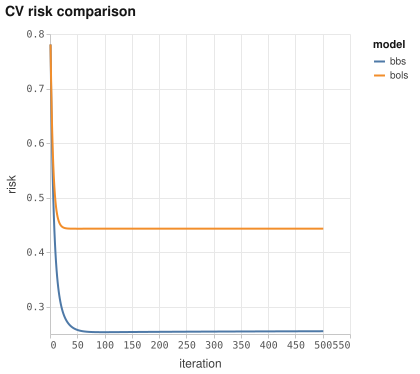

In [13]:
fit2 = mb.gamboost("y ~ bols(x)", data={"x": x, "y": y},
                   family=mb.Gaussian(), control=mb.boost_control(500, 0.1))
cv2 = fit2.cvrisk(type="kfold", B=10, seed=0)
m_opt2 = cv2.optimal_mstop
cvr = fit.cvrisk(type="kfold", B=10, seed=0)
rows = []
for name, cv_obj in [("bbs", cvr), ("bols", cv2)]:
    for i, risk in enumerate(cv_obj.aggregate):
        rows.append({"iteration": i + 1, "risk": risk, "model": name})
import polars as pl
import altair as alt
df_cv = pl.DataFrame(rows)
alt.Chart(df_cv).mark_line().encode(
    x="iteration", y=alt.Y("risk", scale=alt.Scale(zero=False)),
    color="model"
).properties(title="CV risk comparison")

The nonlinear fit has lower estimated loss under these folds and this tuning
rule. That comparison applies to the same response, held-out rows, weights, score,
and aggregation; changing one of them changes the target. `evaluate_specification`
retains those identities with every out-of-fold prediction. The `cv_risk` helper returns a float by default; `return_result=True` returns the full result.

Each result reports its actual model-fit count, including inner tuning fits.
`compare_specifications(..., fit_budget=...)` derives the complete requirement before
fitting and refuses when the candidate list would exceed it. Comparison rows retain each
candidate's fit count, cumulative count, planned total, and optional reconstructible
evaluation object, so a search history states its computational budget as well as its score.

Two further row fields describe the search rather than one candidate.
`search optimism` estimates how optimistic the winning score is because it
is the best of the candidates compared: for each fold it takes the
winner's score minus the lowest score any candidate reached on that fold,
and averages over folds, in the score's own units (Tibshirani &
Tibshirani 2009). A winner that won every fold carries zero; the estimate
grows with the number of candidates tried and the number of folds the
winner lost. `competitive set` lists the candidates whose out-of-fold risk
is within one paired fold standard error of the winner's, winner included:
the folds cannot distinguish those candidates, so preferring one of them
on this comparison alone is a choice the comparison does not support.

A search usually spans several calls: a first comparison, a term report,
then the candidates it suggested. Pass the earlier rows as `history=`
(produced with `include_evaluations=True`) and those two fields describe
the whole search — every candidate tried, in the order tried — while each
row also carries `search candidates` and `search fits`, the count of
candidates and model fits across every call, history first. Rows whose
data, folds or score do not pair with the current call are refused rather
than averaged in.

Use data excluded from the entire search to evaluate the selected model.
`holdout` splits the data before fitting and returns search and test parts:
`holdout(data, fraction=0.2)` deals rows at random, `groups=` deals whole
groups so the test part holds groups the search never saw, and `time=`
takes the most recent rows, each matching the task its score describes.
Fit, tune and compare on the search part only, and score the test part
once, from predictions of a model fitted on the search part. The
evaluation functions warn, from the second specification pointed at the
same test rows, that reusing these rows can influence model selection; a hand-written
predict-and-score loop is not intercepted.


In [14]:
comparison_folds = mb.cv_weights(len(y), type="kfold", B=5, seed=0)
smooth_evaluation = mb.evaluate_specification(
    "bbs(x, df=4)", {"x": x, "y": y}, "y",
    folds=comparison_folds, mstop=200, score="mse",
)
linear_evaluation = mb.evaluate_specification(
    "bols(x)", {"x": x, "y": y}, "y",
    folds=comparison_folds, mstop=200, score="mse",
)
smooth_evaluation.assert_comparable(linear_evaluation)
pl.DataFrame([
    {"model": "smooth", "held-out MSE": smooth_evaluation.score},
    {"model": "linear", "held-out MSE": linear_evaluation.score},
])


model,held-out MSE
str,f64
"""smooth""",0.25577
"""linear""",0.444437


## Cross-validation in R

The R binding supports `cvrisk` for `glmboost` and `gamboost` models. The
workflow uses `cv_weights()` to generate folds, then passes them to `cvrisk()`:

```r
library(mboostrs)
set.seed(5)
n <- 300
x <- runif(n, -3, 3)
y <- sin(x) + rnorm(n, sd = 0.5)
data <- data.frame(x, y)

fit <- glmboost(y ~ x, data = data, family = Gaussian(),
                control = boost_control(500, 0.1))

folds <- cv_weights(n, type = "kfold", B = 10, seed = 0)
cvr <- cvrisk(fit, folds = folds)
m_opt <- mstop(cvr)
cat("R optimal mstop:", m_opt, "\n")
```

```{tip}
`cvrisk` is the default recommendation: its criterion is the family's own held-out loss, so it works for every
family. Reserve AIC for quick, likelihood-based screening. Set `parallel=True`
(default) to spread folds across cores.
```

## GAIC table and model comparison

`logLik` follows the family's likelihood contract, including normalization
where available. Gaussian tables report `mboost_corrected`, the normalized corrected AIC (AICc) that R `mboost` reports, as defined in [](glmboost.ipynb). Likelihood and LSS heuristic criteria have different
labels and cannot be ranked against that criterion. Compare fits on the
same observations and weights. Each row's risk, logLik and mstop refer to
the same criterion-selected iteration.

Use `gaic_table()` to compare fits on the same observations under the same
criterion definition. For these Gaussian fits the column is `mboost_corrected`:

In [15]:
gam_smooth = mb.gamboost("y ~ bbs(x, df=4)", data={"x": x, "y": y},
                         family=mb.Gaussian(), control=mb.boost_control(500, 0.1))
gam_linear = mb.gamboost("y ~ bols(x)", data={"x": x, "y": y},
                         family=mb.Gaussian(), control=mb.boost_control(500, 0.1))

mb.gaic_table(gam_smooth, gam_linear, labels=["smooth bbs", "linear bols"],
              output="auto")

label,mboost_corrected,criterion,normalization,df_convention,df,penalty,mstop,risk,logLik,mboost_corrected_mstop,n
str,f64,str,str,str,f64,null,i64,f64,f64,i64,f64
"""smooth bbs""",-0.359828,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",5.456062,null,93,73.686345,-215.086815,93,300.0
"""linear bols""",0.19633,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",1.982544,null,45,131.625603,-302.108422,45,300.0


Use `compare_models()` for multi-metric comparison (risk, logLik, GAIC, mstop)
and `scan_lss_families()` to try multiple distributional families on the same
formula, collecting failures instead of crashing:

In [16]:
mb.compare_models(gam_smooth, gam_linear, metrics=("risk", "logLik", "GAIC"),
                  labels=["smooth bbs", "linear bols"], output="auto")

label,risk,logLik,GAIC,criterion,normalization,df_convention,df,penalty
str,f64,f64,f64,str,str,str,f64,null
"""smooth bbs""",73.686345,-215.086815,-0.359828,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",5.456062,null
"""linear bols""",131.625603,-302.108422,0.19633,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",1.982544,null


To evaluate a standard model at different `mstop` values without refitting, use
the stored boosting path:

In [17]:
pl.DataFrame(mb.profile_mstop(gam_smooth, grid=[1, 50, 100, 200, 500],
                              metric="risk"))

mstop,risk
i64,f64
1,209.349181
50,75.135056
100,73.648393
200,73.447261
500,73.111191


## Prediction contributions

`predict(which=..., aggregate=...)` decomposes a prediction into per-learner contributions: `aggregate="none"` returns per-step contributions and `aggregate="sum"` the aggregated contribution of a specific learner.

In [18]:
# Contribution of the x learner along the path.
contrib = gam_smooth.predict(which="x", aggregate="cumsum")
contrib.shape

(500, 300)

## Nested cross-validation for `mstop` selection and evaluation

`cvrisk`'s minimum is itself a biased estimate of true test performance when
reused as the reported number: the same data chose `mstop` *and* evaluated
it. Nested CV separates the two: an outer split holds out a test fold
entirely, an inner `cvrisk` (on the training fold only) picks `mstop`, and
the held-out fold evaluates the model selected by that inner procedure. Repeat over outer
folds and average:

In [19]:
from sklearn.model_selection import KFold

outer_kf = KFold(n_splits=5, shuffle=True, random_state=0)
nested_test_mse = []
for train_idx, test_idx in outer_kf.split(x):
    data_train = {"x": x[train_idx], "y": y[train_idx]}
    data_test = {"x": x[test_idx], "y": y[test_idx]}
    fit_outer = mb.gamboost("y ~ bbs(x, df=4)", data=data_train, family=mb.Gaussian(),
                            control=mb.boost_control(500, 0.1))
    m_opt_outer = fit_outer.cvrisk(type="kfold", B=5, seed=0).optimal_mstop  # inner CV
    pred_test = fit_outer[:m_opt_outer].predict(newdata=data_test, type="response")
    nested_test_mse.append(np.mean((pred_test - y[test_idx]) ** 2))

print(f"nested CV test MSE: {np.mean(nested_test_mse):.4f} "
      f"(+/- {np.std(nested_test_mse):.4f} across outer folds)")

# The optimistic comparison: reuse the same data both to pick mstop and to
# "evaluate" it, in-sample.
m_opt_naive = fit.cvrisk(type="kfold", B=5, seed=0).optimal_mstop
pred_naive = fit[:m_opt_naive].predict(newdata={"x": x}, type="response")
naive_mse = np.mean((pred_naive - y) ** 2)
print(f"naive in-sample MSE at the same-data-selected mstop: {naive_mse:.4f}")


nested CV test MSE: 0.2585 (+/- 0.0459 across outer folds)
naive in-sample MSE at the same-data-selected mstop: 0.2456


The naive number is optimistic (lower) because the training data both
selects and evaluates `mstop`; the nested estimate holds each test fold out
completely from both the fit and the `mstop` selection.
Report the nested number when comparing `mboostrs` against other libraries
or claiming a performance figure — `cvrisk`'s own minimum is for *choosing*
`mstop`, not for *reporting* accuracy.

## Per-parameter `mstop` grid for LSS models

`gamboostLSS`/`glmboostLSS` fit one boosting path per distribution
parameter, so cyclic fitting has one `mstop` per parameter rather than a
single scalar. `cvrisk_glmboostLSS` searches a grid of per-parameter `mstop`
vectors directly against the joint out-of-bag negative log-likelihood:

In [20]:
rng_lss = np.random.default_rng(4)
n_lss = 400
x1_lss = rng_lss.uniform(-2, 2, n_lss)
x2_lss = rng_lss.uniform(-2, 2, n_lss)
mu_lss = 1.0 + 2.0 * x1_lss
sigma_lss = np.exp(0.3 + 0.5 * x2_lss)
y_lss = mu_lss + sigma_lss * rng_lss.normal(size=n_lss)
data_lss = {"x1": x1_lss, "x2": x2_lss, "y": y_lss}

lss_folds = mb.cv_weights(n_lss, type="kfold", B=5, seed=0)
mstop_grid = [[m, m] for m in [20, 50, 100, 150]]     # one mstop per parameter (mu, sigma)
lss_result = mb.cvrisk_glmboostLSS(
    "y ~ x1 + x2", data=data_lss, family=mb.GaussianLSS(),
    control=mb.boost_control(200, 0.1), folds=lss_folds, grid=mstop_grid,
)
print(f"grid: {mstop_grid}")
print(f"mean OOB risk per grid point: {lss_result['risk'].mean(axis=0)}")
print(f"selected (mu_mstop, sigma_mstop): {lss_result['mstop']}")


grid: [[20, 20], [50, 50], [100, 100], [150, 150]]
mean OOB risk per grid point: [2.31012273 2.00565981 1.78006042 1.77605346]
selected (mu_mstop, sigma_mstop): [150, 150]


/tmp/ipykernel_67933/1952206577.py:12: RuntimeWarning: the lowest cross-validated risk is at [150, 150], the largest budget in the grid, so the reported optimum is where the search stopped rather than where the risk turns. Extend the grid -- mb.diagonal_grid(300, 2) -- and refit with a control whose mstop covers it.
  lss_result = mb.cvrisk_glmboostLSS(


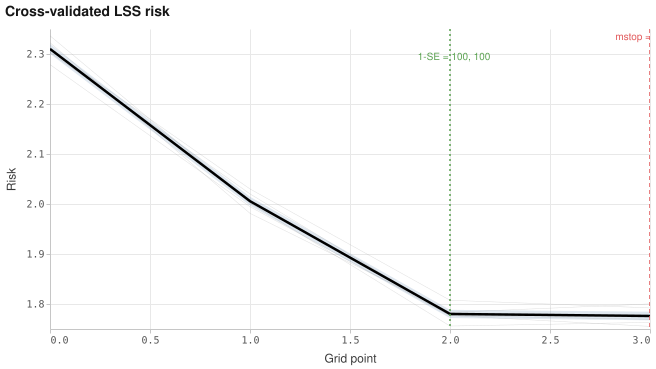

In [21]:
mb.plot.plot_lss_cvrisk(lss_result)


This grid ties `mu` and `sigma` to the same `mstop` for simplicity; a full
independent grid (different `mstop` values per parameter) is a larger search
but uses the identical `grid=` interface — each entry is any length-`K`
vector matching the family's parameter count. See
[](../methodology/gamlss) for the cyclic-fitting mechanics this grid search
is tuning.

## See also

- [](../methodology/model_selection) — the theory behind AIC, cross-validated
  risk, and the bias-variance trade-off in mstop selection.
- [](../methodology/functional_gradient_boosting) — how the risk decreases
  monotonically in training and why early stopping works.
- [](../implementation/frontends) — the Python/R front-end code that
  orchestrates the cvrisk bootstrap and fold management.

## Comparative studies

[Repeated validation of specification search](../cases/specification_search_validation.ipynb) evaluates the entire specification and stopping procedure on fresh test samples. The [Munich rents study](../cases/munich_rents_distributional.ipynb) nests specification and stopping choices within district folds.